<center><h1>Практическое задание</h1></center>

1. Подобрать свой собственный набор данных
2. Выполнить на нём аугментации
3. Собрать единый набор данных из оригинального и аугментированного датасетов
4. Обучить простейшую CNN с ипользованием аугментированных данных

In [8]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from numpy import random

In [2]:
train_dataset = datasets.CIFAR10(root='./Cifar10', train=True, download=True, transform=transforms.ToTensor())


d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [3]:
print(train_dataset)
print(train_dataset[0][0])

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: ./Cifar10
    Split: Train
    StandardTransform
Transform: ToTensor()
tensor([[[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
         [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
         [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
         ...,
         [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
         [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
         [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]],

        [[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
         [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
         [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
         ...,
         [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
         [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
         [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]],

        [[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.

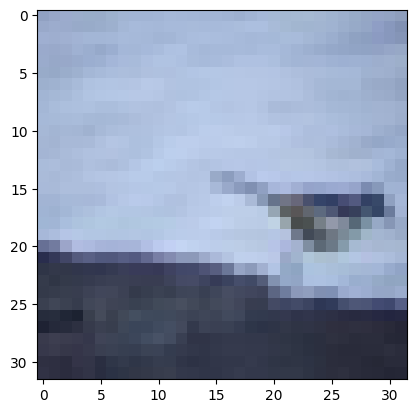

In [4]:
base_transform = transforms.Compose([
    transforms.ToPILImage()
])

plt.imshow(base_transform(train_dataset[49995][0]))
plt.show()

In [29]:
transform_train = transforms.Compose([
    transforms.RandomCrop(size=(32, 32), padding=4),
    transforms.RandomHorizontalFlip(p=.5),
    # transforms.RandomVerticalFlip(p=.2), c ним 72% точности, без 76%
    transforms.ColorJitter(brightness=0.2, contrast=0.3, saturation=0.3, hue=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
])

transforms_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
])

In [30]:
from torch.utils.data import ConcatDataset


train_augmented_dataset = datasets.CIFAR10('./Cifar10', train=True, download=True, transform=transform_train)
train_dataset = datasets.CIFAR10('./Cifar10', train=True, download=True, transform=transforms_test)
test_dataset = datasets.CIFAR10('./Cifar10', train=False, download=True, transform=transforms_test)

train_dataset = ConcatDataset([train_augmented_dataset, train_dataset])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print('Len Train Dataser: ', len(train_dataset))
print('Len Test Dataser: ', len(test_dataset))

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Len Train Dataser:  100000
Len Test Dataser:  10000


In [35]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1) # 32x32x16
        self.pool = nn.MaxPool2d(kernel_size=2) # 16x16x16
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1) #16x16x32
        # 8x8x32
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1) # 8x8x64
        # 4x4x64
        self.activation = nn.ReLU()
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(in_features=4*4*128, out_features=1024)
        self.dropout = nn.Dropout(p=.2)
        self.linear2 = nn.Linear(in_features=1024, out_features=256)
        self.linear3 = nn.Linear(in_features=256, out_features=10)
        self.layers = [self.conv1, self.pool, self.activation,
                       self.conv2, self.pool, self.activation,
                       self.conv3, self.pool, self.activation,
                       self.flatten, self.linear1, self.activation,
                       self.dropout,
                       self.linear2, self.activation, self.linear3]
        
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
# 76%
# class SimpleCNN(nn.Module):
#     def __init__(self):
#         super(SimpleCNN, self).__init__()
#         self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1) # 32x32x16
#         self.pool = nn.MaxPool2d(kernel_size=2) # 16x16x16
#         self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1) #16x16x32
#         # 8x8x32
#         self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1) # 8x8x64
#         # 4x4x64
#         self.activation = nn.ReLU()
#         self.flatten = nn.Flatten()
#         self.linear1 = nn.Linear(in_features=4*4*64, out_features=512)
#         self.linear2 = nn.Linear(in_features=512, out_features=256)
#         self.linear3 = nn.Linear(in_features=256, out_features=10)
#         self.layers = [self.conv1, self.pool, self.activation,
#                        self.conv2, self.pool, self.activation,
#                        self.conv3, self.pool, self.activation,
#                        self.flatten, self.linear1, self.activation,
#                        self.linear2, self.activation, self.linear3]
        
#     def forward(self, x):
#         for layer in self.layers:
#             x = layer(x)
#         return x

In [36]:
device = 'cuda' if torch.cuda.is_available else 'cpu'
print('Current device: ', device)
model = SimpleCNN().to(device)
model

Current device:  cuda


SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (activation): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=2048, out_features=1024, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (linear2): Linear(in_features=1024, out_features=256, bias=True)
  (linear3): Linear(in_features=256, out_features=10, bias=True)
)

In [37]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [38]:
EPOCHS = 20
for epoch in range(EPOCHS):
    train_loss = []
    test_loss = []
    print('Starting epoch ', epoch + 1)
    model.train()
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        train_loss.append(loss.item())
        optimizer.step()

    model.eval()
    with torch.inference_mode():
        total_correct = 0
        total_samples = len(test_loader.dataset)
        for data, targets in test_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            test_loss.append(loss.item())
            classes = torch.argmax(outputs, dim=-1)
            total_correct += (classes == targets).sum().item()
    print(f'Epoch {epoch + 1} train_loss: {np.mean(train_loss)} valid_loss: {np.mean(test_loss)} accuracy: {100 * total_correct / total_samples}%')


Starting epoch  1
Epoch 1 train_loss: 1.6516251451146962 valid_loss: 1.2705404652824885 accuracy: 54.55%
Starting epoch  2
Epoch 2 train_loss: 1.3061042369670466 valid_loss: 1.0712607389763942 accuracy: 62.34%
Starting epoch  3
Epoch 3 train_loss: 1.1311184388662254 valid_loss: 0.9434762966783741 accuracy: 66.78%
Starting epoch  4
Epoch 4 train_loss: 1.0221249465750184 valid_loss: 0.9115639909913268 accuracy: 67.89%
Starting epoch  5
Epoch 5 train_loss: 0.9395189839185848 valid_loss: 0.8256915453114088 accuracy: 70.99%
Starting epoch  6
Epoch 6 train_loss: 0.870162499156886 valid_loss: 0.778930482230609 accuracy: 73.3%
Starting epoch  7
Epoch 7 train_loss: 0.8134432180104771 valid_loss: 0.7536618490762348 accuracy: 73.95%
Starting epoch  8
Epoch 8 train_loss: 0.7643896699218664 valid_loss: 0.6978376568118229 accuracy: 76.15%
Starting epoch  9
Epoch 9 train_loss: 0.7201636057973899 valid_loss: 0.6905588405796245 accuracy: 76.57%
Starting epoch  10
Epoch 10 train_loss: 0.678413566628558 

Делаем класс для блюров и размытия с cv2

In [39]:
# class CV2Blur():
#     def __init__(self, p):
#         self.p = p
    
#     def __work__(self, x):
#         if random.random() < self.p:
#             return x
        
#         x_np = np.array(x)
#         x_bgr = cv.cvtColor(x_np, cv.COLOR_RGB2BGR)

#         method = random.choice(['stack', 'gaussian', 'median', 'bilateral', 'motion'])

#         match method:
#             case 'stack':
#                 ksize = random.choice([3, 5])
#                 result = cv.stackBlur(x_bgr, ksize=ksize)
#             case 'gaussian':
#                 ksize = random.choice([3, 5])
#                 sigmaX = random.uniform(0, 2.0)
#                 result = cv.GaussianBlur(x_bgr, ksize=(ksize, ksize), sigmaX=sigmaX, borderType=cv.BORDER_DEFAULT)
#             case 'median':
#                 ksize = random.choice([3, 5])
#                 result = cv.medianBlur(x_bgr, ksize=ksize)
#             case 'bilateral':
#                 d = random.choice([3, 5, 9])
#                 sigma_color = random.uniform(50, 100)
#                 sigma_space = random.uniform(50, 100)
#                 result = cv.bilateralFilter(x_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)
#             case 'motion':
#                 result = cv.motion
#         cv.stackBlur()

        